# Task 4 – Data Science Tool Mastery Project

**Student:** Nandigam Praveen Kumar  
**Internship:** YuvaIntern – Data Analyst  
**Dataset:** UCI Student Performance  
**Purpose:** Demonstrate Python, NumPy, Pandas, Matplotlib, Seaborn and Scikit-learn in a reproducible workflow.

> Run the notebook from top to bottom. Review the actual outputs before writing numerical findings in the Word report.

## 1. Environment setup

In [1]:
%pip -q install ucimlrepo

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the real-world dataset

In [3]:
# UCI Machine Learning Repository dataset ID: 320
student_performance = fetch_ucirepo(id=320)

features = student_performance.data.features.copy()
targets = student_performance.data.targets.copy()

print("Feature data shape:", features.shape)
print("Target data shape:", targets.shape)
display(features.head())
display(targets.head())

Feature data shape: (649, 30)
Target data shape: (649, 3)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,6
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,0


,G1,G2,G3
0,0,11,11
1,9,11,11
2,12,13,12
3,14,14,14
4,11,13,13


In [4]:
# Combine features and target columns for analysis.
df = pd.concat([features.reset_index(drop=True), targets.reset_index(drop=True)], axis=1)

# Normalize column labels to strings and remove accidental surrounding spaces.
df.columns = [str(c).strip() for c in df.columns]

print("Combined dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.info())

Combined dataset shape: (649, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11 

None

## 3. Pandas: inspect data quality

In [5]:
display(df.head(10))
display(df.describe(include="all").T)

quality_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality_summary)

print("Duplicate rows:", df.duplicated().sum())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,6,12,12,13
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,13,12,13
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,2,10,13,13
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,15,16,17
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,12,12,13


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,data_type,missing_count,missing_percent,unique_values
school,object,0,0.0,2
sex,object,0,0.0,2
age,int64,0,0.0,8
address,object,0,0.0,2
famsize,object,0,0.0,2
Pstatus,object,0,0.0,2
Medu,int64,0,0.0,5
Fedu,int64,0,0.0,5
Mjob,object,0,0.0,5
Fjob,object,0,0.0,5


Duplicate rows: 0


In [6]:
# Create a working copy. Remove exact duplicate rows if any are present.
clean_df = df.drop_duplicates().copy()

# Convert columns that are numeric but imported as text, where possible.
for col in clean_df.columns:
    if clean_df[col].dtype == "object":
        converted = pd.to_numeric(clean_df[col], errors="coerce")
        # Only convert when conversion succeeds for most non-missing values.
        non_missing = clean_df[col].notna().sum()
        if non_missing and converted.notna().sum() / non_missing >= 0.95:
            clean_df[col] = converted

print("Rows before:", len(df))
print("Rows after removing exact duplicates:", len(clean_df))
print("Missing values remaining:", int(clean_df.isna().sum().sum()))

Rows before: 649
Rows after removing exact duplicates: 649
Missing values remaining: 0


## 4. NumPy: numerical operations

In [7]:
numeric_cols = clean_df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)

if numeric_cols:
    numeric_array = clean_df[numeric_cols].to_numpy(dtype=float)
    print("NumPy array shape:", numeric_array.shape)
    print("Column means (ignoring NaN):")
    print(np.nanmean(numeric_array, axis=0))
    print("Column standard deviations (ignoring NaN):")
    print(np.nanstd(numeric_array, axis=0))

Numeric columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
NumPy array shape: (649, 16)
Column means (ignoring NaN):
[16.74422188  2.5146379   2.30662558  1.56856703  1.93066256  0.22187982
  3.93066256  3.18027735  3.18489985  1.50231125  2.28043143  3.53620955
  3.65947612 11.3990755  11.57010786 11.90600924]
Column standard deviations (ignoring NaN):
[1.2171988  1.13367759 1.09908318 0.74808308 0.82887026 0.59277794
 0.95498031 1.05028248 1.17485994 0.92412165 1.28339008 1.4451444
 4.63718212 2.74314932 2.91139309 3.22816633]


## 5. Pandas: filtering, sorting and grouping

In [8]:
# Examples of common analytical operations.
if "G3" in clean_df.columns:
    grade_col = "G3"
    print("Final-grade summary:")
    display(clean_df[grade_col].describe())

    print("Ten records with the highest final grades:")
    display(clean_df.sort_values(grade_col, ascending=False).head(10))

    if "studytime" in clean_df.columns:
        print("Final grade by study-time category:")
        display(clean_df.groupby("studytime", dropna=False)[grade_col].agg(
            count="count", mean="mean", median="median"
        ).round(2))

    if "failures" in clean_df.columns:
        print("Final grade by previous-failure category:")
        display(clean_df.groupby("failures", dropna=False)[grade_col].agg(
            count="count", mean="mean", median="median"
        ).round(2))
else:
    raise ValueError("Expected target column G3 was not found. Inspect the dataset columns above.")

Final-grade summary:


,G3
count,649.000000
mean,11.906009
std,3.230656
min,0.000000
25%,10.000000
50%,12.000000
75%,14.000000
max,19.000000


Ten records with the highest final grades:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
636,MS,M,18,U,GT3,T,4,4,teacher,teacher,...,3,2,4,1,4,2,4,17,18,19
338,GP,F,17,R,LE3,T,3,1,services,other,...,3,1,2,1,1,3,0,18,19,19
596,MS,F,17,U,GT3,T,4,2,other,other,...,4,3,3,1,2,4,0,17,18,18
113,GP,M,15,U,LE3,T,4,2,teacher,other,...,3,5,2,1,1,3,10,18,17,18
617,MS,F,18,U,LE3,T,1,1,at_home,services,...,5,3,2,1,1,4,0,19,17,18
416,GP,M,17,U,LE3,A,3,2,other,other,...,4,4,4,1,2,5,10,16,18,18
332,GP,F,18,U,GT3,T,2,2,at_home,at_home,...,4,3,3,1,2,2,0,18,18,18
509,MS,F,16,R,LE3,T,1,1,at_home,other,...,5,3,2,1,1,1,0,16,17,18
327,GP,F,18,R,LE3,T,1,1,at_home,other,...,5,2,2,1,1,3,2,17,17,18
314,GP,M,17,R,GT3,T,1,2,at_home,at_home,...,3,5,2,2,2,1,2,16,17,18


Final grade by study-time category:


,count,mean,median
studytime,,,
1,212,10.84,11.0
2,305,12.09,12.0
3,97,13.23,13.0
4,35,13.06,13.0


Final grade by previous-failure category:


,count,mean,median
failures,,,
0,549,12.51,12.0
1,70,8.64,10.0
2,16,8.81,9.5
3,14,8.07,8.5


## 6. Matplotlib and Seaborn: visual exploration

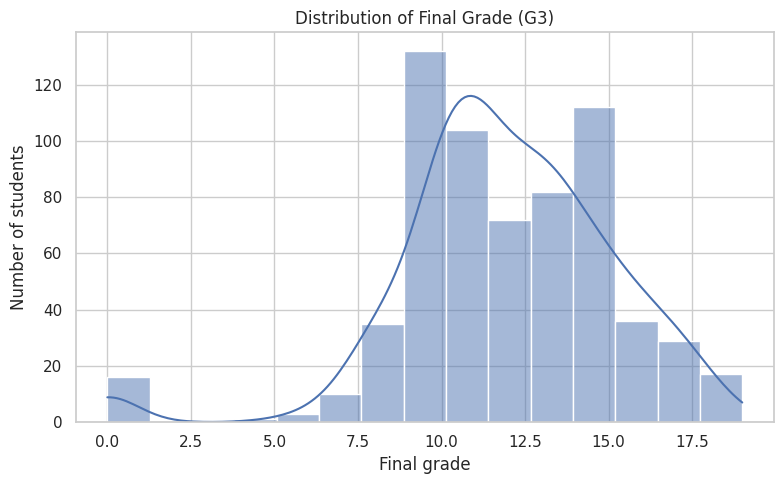

In [9]:
# Distribution of the final grade.
plt.figure(figsize=(8, 5))
sns.histplot(data=clean_df, x="G3", bins=15, kde=True)
plt.title("Distribution of Final Grade (G3)")
plt.xlabel("Final grade")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

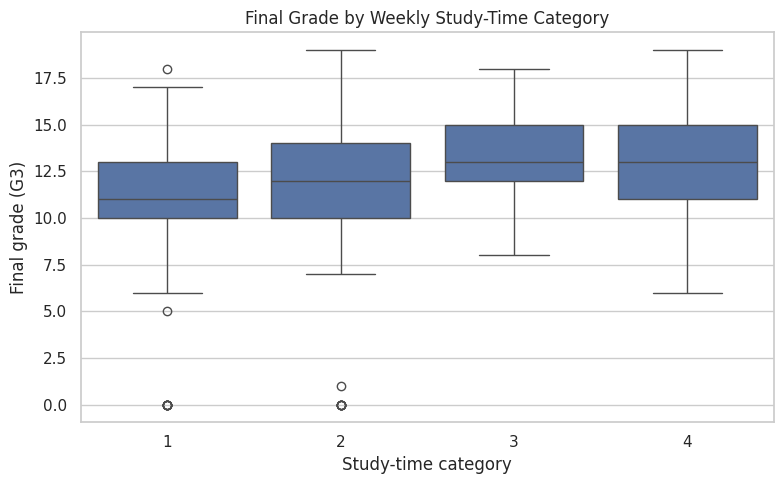

In [10]:
# Box plot: final grade across study-time categories.
if "studytime" in clean_df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=clean_df, x="studytime", y="G3")
    plt.title("Final Grade by Weekly Study-Time Category")
    plt.xlabel("Study-time category")
    plt.ylabel("Final grade (G3)")
    plt.tight_layout()
    plt.show()

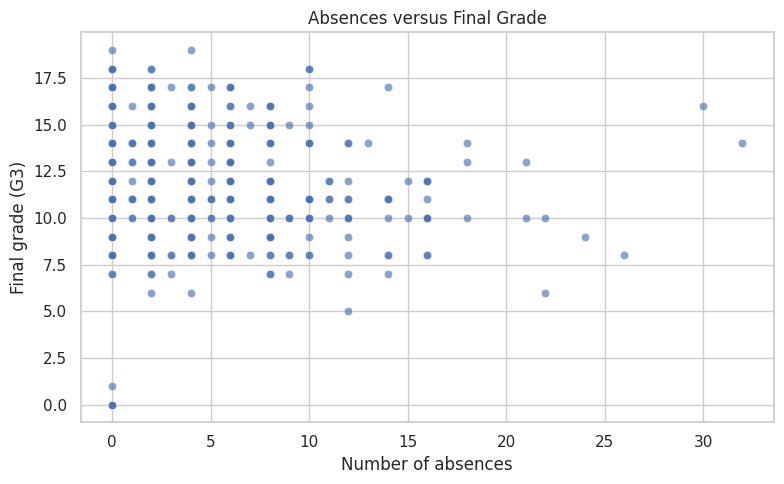

Pearson correlation (absences, G3): -0.091


In [11]:
# Scatter plot: absences versus final grade.
if "absences" in clean_df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=clean_df, x="absences", y="G3", alpha=0.65)
    plt.title("Absences versus Final Grade")
    plt.xlabel("Number of absences")
    plt.ylabel("Final grade (G3)")
    plt.tight_layout()
    plt.show()
    print("Pearson correlation (absences, G3):",
          round(clean_df[["absences", "G3"]].corr().iloc[0, 1], 3))

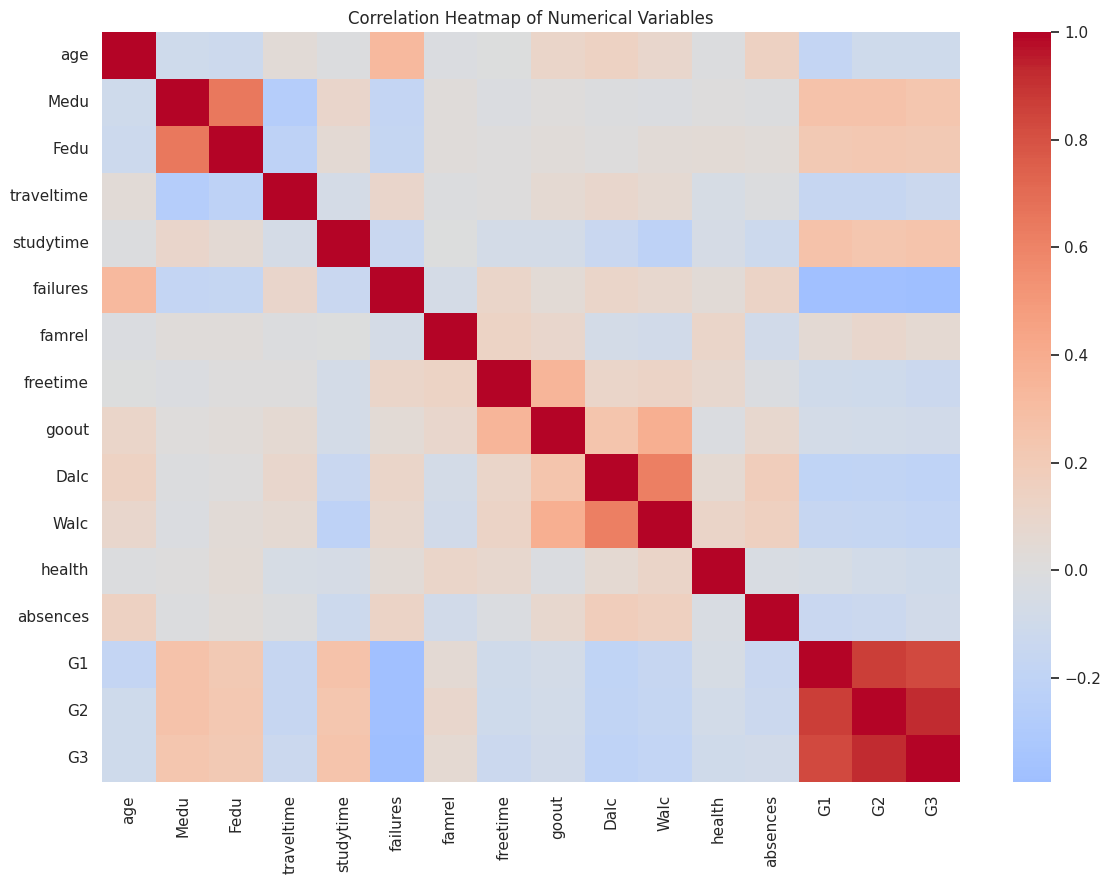

Numerical correlations with G3:


,correlation_with_G3
G3,1.000000
G2,0.918548
G1,0.826387
studytime,0.249789
Medu,0.240151
Fedu,0.211800
famrel,0.063361
goout,-0.087641
absences,-0.091379
health,-0.098851


In [12]:
# Correlation heatmap for numeric variables.
numeric_df = clean_df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr()
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation Heatmap of Numerical Variables")
    plt.tight_layout()
    plt.show()

    if "G3" in corr.columns:
        print("Numerical correlations with G3:")
        display(corr["G3"].sort_values(ascending=False).to_frame("correlation_with_G3"))

## 7. Scikit-learn: baseline regression model

The model below excludes `G1` and `G2` by default. These earlier grades are closely related to the final grade and can create information leakage if the intended use is to predict outcomes before those grades are available. This is an educational baseline, not a high-stakes prediction system.

In [13]:
target = "G3"
excluded_from_features = [target, "G1", "G2"]
feature_cols = [c for c in clean_df.columns if c not in excluded_from_features]

model_df = clean_df[feature_cols + [target]].copy()
model_df = model_df.dropna(subset=[target])

X = model_df[feature_cols]
y = pd.to_numeric(model_df[target], errors="coerce")
valid_target = y.notna()
X, y = X.loc[valid_target], y.loc[valid_target]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R-squared: {r2:.3f}")

Training rows: 519
Test rows: 130
MAE: 2.152
RMSE: 2.858
R-squared: 0.162


,actual_G3,predicted_G3
0,19,13.071492
1,12,12.962689
2,18,14.007196
3,11,12.016581
4,11,10.375105
5,17,12.688895
6,18,13.811015
7,8,6.692069
8,10,12.591954
9,11,12.150984


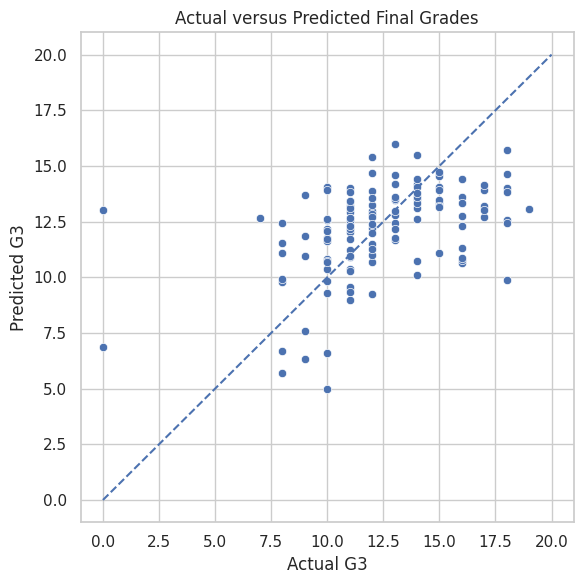

In [14]:
# Compare actual and predicted values.
comparison = pd.DataFrame({
    "actual_G3": y_test.to_numpy(),
    "predicted_G3": predictions
})
display(comparison.head(15))

plt.figure(figsize=(6, 6))
sns.scatterplot(data=comparison, x="actual_G3", y="predicted_G3")
plt.plot([0, 20], [0, 20], linestyle="--")
plt.title("Actual versus Predicted Final Grades")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.tight_layout()
plt.show()

## 8. Automatically generated observations

In [15]:
observations = []
if "studytime" in clean_df.columns:
    study_means = clean_df.groupby("studytime")["G3"].mean().dropna()
    if len(study_means) >= 2:
        observations.append(
            f"Mean G3 ranges from {study_means.min():.2f} to {study_means.max():.2f} "
            "across study-time categories. This is an association, not proof of causation."
        )

if "absences" in clean_df.columns:
    r = clean_df[["absences", "G3"]].corr().iloc[0, 1]
    observations.append(f"Pearson correlation between absences and G3 = {r:.3f}.")

if "failures" in clean_df.columns:
    fail_means = clean_df.groupby("failures")["G3"].mean().dropna()
    if len(fail_means) >= 2:
        observations.append(
            f"Mean G3 ranges from {fail_means.min():.2f} to {fail_means.max():.2f} "
            "across previous-failure categories."
        )

for i, observation in enumerate(observations, 1):
    print(f"{i}. {observation}")

print("\nLimitations: observational data from two Portuguese schools; results may not generalize.")

1. Mean G3 ranges from 10.84 to 13.23 across study-time categories. This is an association, not proof of causation.
2. Pearson correlation between absences and G3 = -0.091.
3. Mean G3 ranges from 8.07 to 12.51 across previous-failure categories.

Limitations: observational data from two Portuguese schools; results may not generalize.


## 9. Export cleaned data and summary

In [16]:
clean_df.to_csv("student_performance_cleaned.csv", index=False)

summary = pd.DataFrame([{
    "rows_after_cleaning": len(clean_df),
    "columns": clean_df.shape[1],
    "duplicate_rows_after_cleaning": int(clean_df.duplicated().sum()),
    "missing_cells_after_cleaning": int(clean_df.isna().sum().sum()),
    "MAE": float(mae),
    "RMSE": float(rmse),
    "R_squared": float(r2)
}])
display(summary)
summary.to_csv("task4_summary_metrics.csv", index=False)
print("Exported student_performance_cleaned.csv and task4_summary_metrics.csv")

,rows_after_cleaning,columns,duplicate_rows_after_cleaning,missing_cells_after_cleaning,MAE,RMSE,R_squared
0,649,33,0,0,2.151808,2.857986,0.162395


Exported student_performance_cleaned.csv and task4_summary_metrics.csv


## 10. Final checklist

- [ ] Run every cell from top to bottom without errors.
- [ ] Review all printed tables, charts and model metrics.
- [ ] Add actual numerical results and interpretations to the Word report.
- [ ] Save/download the executed notebook with outputs.
- [ ] Upload the notebook and report to the GitHub repository.
- [ ] Include the repository URL in the YuvaIntern submission if required.

**Important:** Do not claim that the model is accurate or useful without evaluating the actual test metrics and considering validation limits.